# Tablas 1 y 2: datasets y positivos esperados en el contexto

- Tabla 1: descripción de cada dataset (tamaño, % de positivos, positivos por partición, faltantes).
- Tabla 2: cuántos positivos tendrá el contexto de TabPFN según la estrategia y el tamaño `m`.

Usamos solo la semilla 0. Los faltantes se miden únicamente en train, como en los EDA anteriores.

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

from tpf.contexts.expected import expected_context_positives
from tpf.data.loaders import SPECS, load_dataset
from tpf.data.splits import load_split, make_split, split_path
from tpf.paths import CONFIGS, REPORTS

SEED = 0
NOMBRES = {"home_credit": "D0 Home Credit", "ulb": "D1 ULB"}
TABLAS = REPORTS / "tables"
FIG_DIR = REPORTS / "figures"
TABLAS.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

cfg = yaml.safe_load((CONFIGS / "default.yaml").read_text(encoding="utf-8"))
TAMANIOS = cfg["context"]["sizes"]
ESTRATEGIAS = cfg["context"]["strategies"]
DATASETS = [d for d in cfg["datasets"] if d in SPECS]

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams["figure.dpi"] = 110
print("Datasets:", DATASETS, "| m:", TAMANIOS, "| estrategias:", ESTRATEGIAS)

Datasets: ['home_credit', 'ulb'] | m: [1000, 5000, 10000] | estrategias: ['uniform', 'stratified', 'balanced', 'nearmiss', 'iht']


## Tabla 1: descripción de los datasets

Para cada dataset cargamos la partición de la semilla 0 y contamos filas, columnas y positivos.

In [8]:
filas = []
stats_train = {}  # (n_train, positivos_train)

for name in DATASETS:
    X, y = load_dataset(name)
    parts = load_split(name, SEED) if split_path(name, SEED).exists() else make_split(y, SEED)
    y_arr = y.to_numpy()
    X_tr = X.iloc[parts["train"]]

    n_tr, pos_tr = len(parts["train"]), int(y_arr[parts["train"]].sum())
    stats_train[name] = (n_tr, pos_tr)

    filas.append(
        {
            "Dataset": NOMBRES.get(name, name),
            "n (filas)": len(y),
            "d (features)": X.shape[1],
            "% positivos": 100 * y_arr.mean(),
            "# pos train": pos_tr,
            "# pos val": int(y_arr[parts["val"]].sum()),
            "# pos test": int(y_arr[parts["test"]].sum()),
            "% celdas faltantes (train)": 100 * X_tr.isna().to_numpy().mean(),
            "% columnas con algún faltante": 100 * (X_tr.isna().mean() > 0).mean(),
        }
    )
    del X, X_tr

tabla1 = pd.DataFrame(filas)
display(tabla1)

,Dataset,n (filas),d (features),% positivos,# pos train,# pos val,# pos test,% celdas faltantes (train),% columnas con algún faltante
0,D0 Home Credit,307511,120,8.073,14895,4965,4965,24.766,55.000
1,D1 ULB,284807,30,0.173,295,98,99,0.000,0.000


## Tabla 2: positivos esperados en el contexto

Para cada dataset, estrategia y `m` calculamos:

- pos esperados: cuántos positivos habrá en el contexto.
- pi_ctx (%): proporción de positivos en el contexto.
- P(0 positivos): probabilidad de que el contexto no tenga ningún positivo (solo tiene sentido en Uniform).
- Capado: Balanced pide 50/50, pero si en train no hay tantos positivos, se usan todos y se completa con negativos.

In [ ]:
filas = []
for name in DATASETS:
    n_tr, pos_tr = stats_train[name]
    for m in TAMANIOS:
        for est in ESTRATEGIAS:
            r = expected_context_positives(n_tr, pos_tr, m, est)
            filas.append(
                {
                    "Dataset": NOMBRES.get(name, name),
                    "m": m,
                    "Estrategia": est + (" (supuesto)" if est in ("nearmiss", "iht") else ""),
                    "# pos esperados": r.n_pos,
                    "pi_ctx (%)": 100 * r.pi_ctx,
                    "P(0 positivos) (%)": 100 * r.p_zero_pos,
                    "Capado": "sí" if r.capped else "no",
                }
            )

tabla2 = pd.DataFrame(filas)
display(tabla2)

,Dataset,m,Estrategia,# pos esperados,π_ctx (%),P(0 positivos) (%),Capado
0,D0 Home Credit,1000,uniform,80.729,8.073,0.000,no
1,D0 Home Credit,1000,stratified,81.000,8.100,0.000,no
2,D0 Home Credit,1000,balanced,500.000,50.000,0.000,no
3,D0 Home Credit,1000,nearmiss (supuesto),500.000,50.000,0.000,no
4,D0 Home Credit,1000,iht (supuesto),500.000,50.000,0.000,no
5,D0 Home Credit,5000,uniform,403.645,8.073,0.000,no
6,D0 Home Credit,5000,stratified,404.000,8.080,0.000,no
7,D0 Home Credit,5000,balanced,"2,500.000",50.000,0.000,no
8,D0 Home Credit,5000,nearmiss (supuesto),"2,500.000",50.000,0.000,no
9,D0 Home Credit,5000,iht (supuesto),"2,500.000",50.000,0.000,no


En ULB, con Uniform y m = 1000 esperamos solo 1,7 positivos, y en 17,67 % de los contextos no hay ninguno.
Balanced en ULB queda capado (solo hay 295 positivos), así que su π_ctx cae a medida que crece `m`.
Es decir, que en desbalance extremo, la cantidad de positivos disponibles limita más que la estrategia.

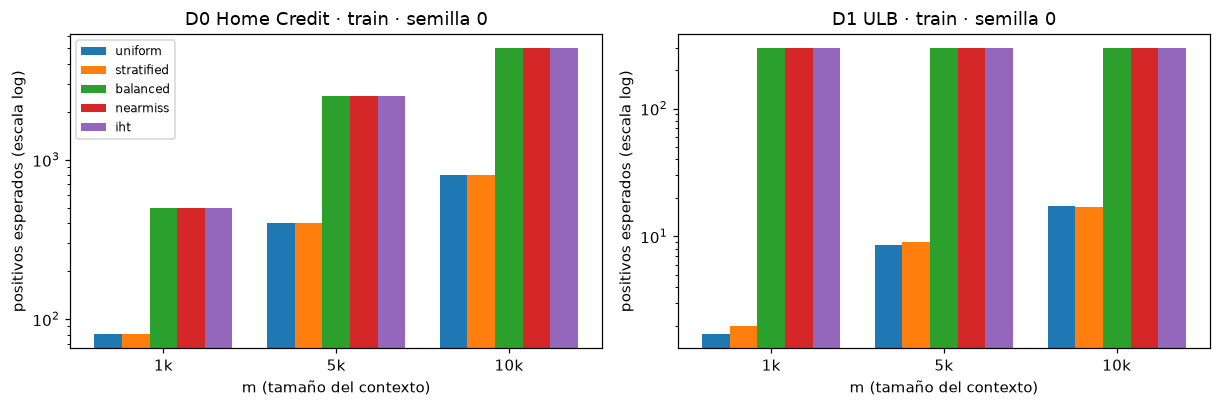

In [4]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5.6 * len(DATASETS), 3.8), squeeze=False)
ancho = 0.8 / len(ESTRATEGIAS)
for ax, name in zip(axes[0], DATASETS, strict=True):
    sub = tabla2[tabla2["Dataset"] == NOMBRES.get(name, name)]
    for i, est in enumerate(ESTRATEGIAS):
        s = sub[sub["Estrategia"].str.startswith(est)]
        pos_x = np.arange(len(TAMANIOS)) + (i - len(ESTRATEGIAS) / 2 + 0.5) * ancho
        ax.bar(pos_x, s["# pos esperados"], width=ancho, label=est)
    ax.set_xticks(range(len(TAMANIOS)))
    ax.set_xticklabels([f"{m // 1000}k" for m in TAMANIOS])
    ax.set_yscale("log")
    ax.set_xlabel("m (tamaño del contexto)")
    ax.set_ylabel("positivos esperados (escala log)")
    ax.set_title(f"{NOMBRES.get(name, name)} · train · semilla {SEED}")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_tabla2_positivos_contexto.png")
plt.show()

In [5]:
def a_markdown(df: pd.DataFrame) -> str:
    df = df.copy()
    for c in df.select_dtypes("number").columns:
        df[c] = df[c].map(lambda v: f"{v:,.2f}" if isinstance(v, float) else f"{v:,}")
    cab = "| " + " | ".join(map(str, df.columns)) + " |"
    sep = "|" + "---|" * len(df.columns)
    cuerpo = ["| " + " | ".join(map(str, fila)) + " |" for fila in df.itertuples(index=False)]
    return "\n".join([cab, sep, *cuerpo]) + "\n"


for nombre, tabla in (("tabla1_datasets", tabla1), ("tabla2_positivos_contexto", tabla2)):
    tabla.to_csv(TABLAS / f"{nombre}.csv", index=False)
    (TABLAS / f"{nombre}.md").write_text(a_markdown(tabla), encoding="utf-8")
print("Guardado en", TABLAS)

Guardado en C:\Users\sebaj\OneDrive\Desktop\BDM-FINAL\FinalBDM\reports\tables
